# Lab 2 — What Did the Campaign Deliver?
Name: Kuksa Zahar | Group: KM-43

## Setup

In [15]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


In [16]:
CLIENT = "BRAND_A"
BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]
SMALL = ["FX", "BRAVO", "HGTV", "FOOD", "HIST"]

def naive(s):
    """Timestamps as plain US-Eastern wall-clock time (drop a timezone label if there is one)."""
    s = pd.to_datetime(s)
    return s.dt.tz_localize(None) if s.dt.tz is not None else s

for df, cols in [(programs, ["start_ts", "end_ts"]), (viewings, ["start_ts", "end_ts"]), (commercials, ["start_ts"])]:
    for c in cols:
        df[c] = naive(df[c])
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"])

dw = daily_weights[daily_weights["resp_type"].isin(["R", "L"])][["respondent_id", "broadcast_date", "weight"]]
mw = dw.groupby("respondent_id")["weight"].mean()

va = viewer_attributes.drop_duplicates(["respondent_id", "attr_id"])
age = pd.to_numeric(va[va["attr_id"] == 300].set_index("respondent_id")["value"], errors="coerce").reindex(mw.index)
sex = (va[va["attr_id"].isin([201, 202])].set_index("respondent_id")["attr_id"]
         .map({201: "M", 202: "W"}).reindex(mw.index))

AUD = {"P2+": mw.index, "A18-49": mw.index[(age >= 18) & (age <= 49)]}
DEN = {a: dw[dw["respondent_id"].isin(ids)].groupby("broadcast_date")["weight"].sum() for a, ids in AUD.items()}
N_IN_TAB = dw.groupby("broadcast_date")["respondent_id"].nunique()

sessions = viewings[viewings["resp_type"].isin(["R", "L"])][["respondent_id", "network_code", "start_ts", "end_ts"]]

def broadcast_info(df):
    """Broadcast date, broadcast weekday (0 = Mon) and minutes since 06:00 of the broadcast day, from start_ts."""
    bt = df["start_ts"] - pd.Timedelta(hours=6)
    return bt.dt.normalize(), bt.dt.weekday, bt.dt.hour * 60 + bt.dt.minute + bt.dt.second / 60

def exposures(spots):
    """One row per (spot, person who saw it): session start <= spot start < session end, same network,
    and the person is in-tab on the spot's broadcast day (weight = that day's weight)."""
    parts = []
    for net, sp in spots.groupby("network_code"):
        sp = sp.sort_values("start_ts")
        S = sp["start_ts"].to_numpy("datetime64[ns]")
        ids = sp["ad_airing_id"].to_numpy()
        ses = sessions[sessions["network_code"] == net]
        st = ses["start_ts"].to_numpy("datetime64[ns]")
        en = ses["end_ts"].to_numpy("datetime64[ns]")
        lo = np.searchsorted(S, st, side="left")      # first spot starting at/after session start
        hi = np.searchsorted(S, en, side="left")      # first spot starting at/after session end
        cnt = np.maximum(hi - lo, 0)
        keep = np.flatnonzero(cnt > 0)
        c = cnt[keep]
        row = np.repeat(keep, c)
        pos = np.arange(c.sum()) - np.repeat(np.cumsum(c) - c, c) + np.repeat(lo[keep], c)
        parts.append(pd.DataFrame({"ad_airing_id": ids[pos],
                                   "respondent_id": ses["respondent_id"].to_numpy()[row]}))
    e = pd.concat(parts, ignore_index=True).drop_duplicates()
    e = e.merge(spots[["ad_airing_id", "network_code", "bdate"]], on="ad_airing_id")
    e = e.merge(dw.rename(columns={"broadcast_date": "bdate"}), on=["respondent_id", "bdate"])   # in-tab that day
    return e

def delivery(expo, spots, a):
    """Impressions, GRPs, reach and average frequency of a set of spots for audience a (P2+ or A18-49)."""
    ids = AUD[a]
    e = expo[expo["ad_airing_id"].isin(spots["ad_airing_id"]) & expo["respondent_id"].isin(ids)]
    imp = e.groupby("ad_airing_id")["weight"].sum().reindex(spots["ad_airing_id"]).fillna(0)
    rating = pd.Series(imp.to_numpy() / spots["bdate"].map(DEN[a]).to_numpy() * 100, index=imp.index)
    grps = rating.sum()
    reach = mw.reindex(e["respondent_id"].unique()).sum() / mw[ids].sum() * 100
    return dict(impressions=imp.sum(), grps=grps, reach=reach,
                freq=grps / reach if reach > 0 else np.nan, spot_imp=imp, spot_rating=rating)

## Task 1.1 — Size

In [17]:
brand_a = commercials[commercials["brand"] == CLIENT]
print("Spots:", commercials["ad_airing_id"].nunique())
print("Pods:", commercials["pod_id"].nunique())
print("Brands:", commercials["brand"].nunique())
print("Categories:", commercials["category"].nunique())
print("BRAND_A spots:", len(brand_a))
print(brand_a.groupby("network_code").size().rename("BRAND_A spots").sort_values(ascending=False).to_string())

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300
network_code
FNC      40
HGTV     39
FX       38
HIST     37
FOOD     33
BRAVO    33
ABC      29
CBS      22
NBC      16
FOX      13


## Task 1.2 — Ad load

In [18]:
OCT_HOURS = 31 * 24
hourly = (commercials.assign(hour=commercials["start_ts"].dt.floor("h"))
          .groupby(["network_code", "hour"])["length_sec"].sum().reset_index())
ad_load = hourly.groupby("network_code").agg(ad_min_per_hour=("length_sec", lambda s: s.mean() / 60),
                                              hours_with_ads=("hour", "nunique"))
ad_load["share_of_clock_hours_with_ads"] = ad_load["hours_with_ads"] / OCT_HOURS
ad_load = ad_load.sort_values("ad_min_per_hour", ascending=False)
print(ad_load.round({"ad_min_per_hour": 2, "share_of_clock_hours_with_ads": 3}).to_string())
print("Heaviest ad load:", ad_load["ad_min_per_hour"].idxmax())

              ad_min_per_hour  hours_with_ads  share_of_clock_hours_with_ads
network_code                                                                
FNC                     15.64             743                          0.999
BRAVO                   13.43             623                          0.837
HGTV                    13.34             621                          0.835
HIST                    13.21             622                          0.836
FOOD                    13.11             620                          0.833
FX                      12.92             621                          0.835
CBS                     12.14             427                          0.574
ABC                     11.84             349                          0.469
NBC                     11.82             299                          0.402
FOX                     11.79             196                          0.263
Heaviest ad load: FNC


**Answer:** The broadcast networks (CBS, NBC, ABC, FOX) hand part of their day to the local stations: local morning and midday news, local news blocks, and similar slots. The breaks in those hours are sold by the stations themselves, so they are not national ads and are not in `commercials`. Those clock hours therefore carry no national spots, which is why the broadcast networks have fewer hours with ads (see the share of clock hours column). Cable networks (FNC, FX, BRAVO, HGTV, FOOD, HIST) run one national feed all day with national breaks in almost every hour, so they have many more hours with ads and usually the heaviest load per hour.

## Task 1.3 — Price everything

In [19]:
rc = rate_card.copy()
rc["program_name"] = rc["program_name"].fillna("").astype(str).str.strip()
prog_rows = rc[rc["program_name"] != ""].drop_duplicates(["network_code", "program_name"])
time_rows = rc[rc["program_name"] == ""].copy()

# every spot gets the name of the program it ran in, plus its broadcast weekday and minute of the broadcast day
sp = commercials.merge(programs[["telecast_id", "program_name"]].drop_duplicates("telecast_id"),
                       on="telecast_id", how="left")
sp["bdate"], sp["bweekday"], sp["bmin"] = broadcast_info(sp)

sp = sp.merge(prog_rows[["network_code", "program_name", "daypart", "cost_30s_usd"]]
              .rename(columns={"daypart": "sell_daypart", "cost_30s_usd": "cost_30s"}),
              on=["network_code", "program_name"], how="left")
sp["price_source"] = np.where(sp["cost_30s"].notna(), "program", "time")

def to_min(t):
    h, m = str(t).split(":")[:2]
    return int(h) * 60 + int(m) - 360

time_rows["t0"] = time_rows["start_time"].map(to_min)
time_rows["t1"] = time_rows["end_time"].map(to_min)
time_rows["bweekday"] = time_rows["weekdays"].map(lambda w: [int(x) for x in w])
tr = time_rows.explode("bweekday").astype({"bweekday": int})

todo = sp.loc[sp["price_source"] == "time", ["ad_airing_id", "network_code", "bweekday", "bmin"]]
m = todo.merge(tr[["network_code", "bweekday", "t0", "t1", "daypart", "cost_30s_usd"]], on=["network_code", "bweekday"])
m = m[(m["bmin"] >= m["t0"]) & (m["bmin"] < m["t1"])]
print("Spots matched by more than one time row (should be 0):", int(m["ad_airing_id"].duplicated().sum()))
m = m.drop_duplicates("ad_airing_id").set_index("ad_airing_id")
sp["sell_daypart"] = sp["sell_daypart"].fillna(sp["ad_airing_id"].map(m["daypart"]))
sp["cost_30s"] = sp["cost_30s"].fillna(sp["ad_airing_id"].map(m["cost_30s_usd"]))

sp["cost"] = sp["cost_30s"] * sp["length_sec"] / 30
spots_all = sp

print("Spots without a price:", int(spots_all["cost"].isna().sum()))
value = spots_all.groupby("network_code")["cost"].sum()
prog_value = spots_all[spots_all["price_source"] == "program"].groupby("network_code")["cost"].sum().reindex(value.index).fillna(0)
value_tbl = pd.DataFrame({"rate_card_value_usd_M": (value / 1e6).round(1),
                          "share_from_program_rows": (prog_value / value).round(3)}).sort_values("rate_card_value_usd_M", ascending=False)
print(value_tbl.to_string())

Spots matched by more than one time row (should be 0): 0
Spots without a price: 0
              rate_card_value_usd_M  share_from_program_rows
network_code                                                
CBS                           818.8                    0.230
NBC                           724.3                    0.342
ABC                           708.8                    0.432
FOX                           696.2                    0.835
FNC                           315.8                    0.000
HGTV                           58.1                    0.000
FX                             42.5                    0.000
FOOD                           42.1                    0.000
HIST                           40.1                    0.000
BRAVO                          25.3                    0.000


## Task 2.1 — Delivery

In [20]:
spots = spots_all[spots_all["brand"] == CLIENT].copy()
expo = exposures(spots)                      # one row per spot and person who saw it (in-tab persons only)
res = {a: delivery(expo, spots, a) for a in AUD}

print("P2+ impressions (M):", round(res["P2+"]["impressions"] / 1e6, 1))
print("P2+ GRPs:", round(res["P2+"]["grps"], 1))
print("P2+ reach (%):", round(res["P2+"]["reach"], 1))
print("P2+ average frequency:", round(res["P2+"]["freq"], 2))
print("A18-49 impressions (M):", round(res["A18-49"]["impressions"] / 1e6, 1))
print("A18-49 GRPs:", round(res["A18-49"]["grps"], 1))
print("A18-49 reach (%):", round(res["A18-49"]["reach"], 1))
print("A18-49 average frequency:", round(res["A18-49"]["freq"], 2))

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.03
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 1.98


## Task 2.2 — Frequency distribution

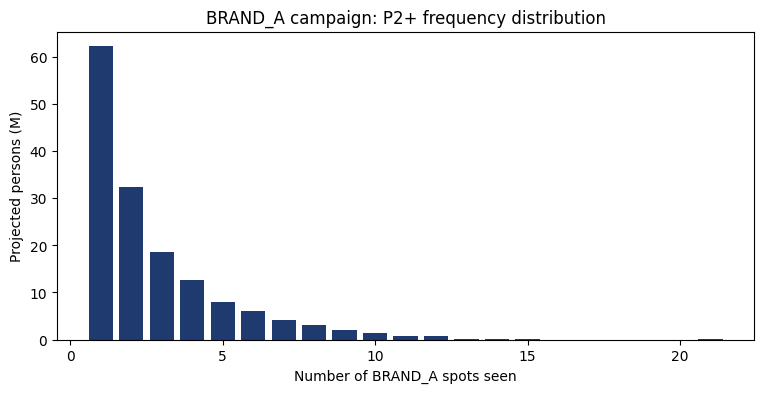

Share of impressions at 5+ exposures: 0.444
Weighted median frequency: 2
Share of reached persons seen once: 0.409


In [21]:
e = expo[expo["respondent_id"].isin(AUD["P2+"])]
freq = e.groupby("respondent_id").size()                      # spots seen per person who saw at least one
dist = mw.reindex(freq.index).groupby(freq.values).sum() / 1e6  # projected persons (M) by number of spots seen

plt.figure(figsize=(9, 4))
plt.bar(dist.index, dist.values, color="#1f3a6e")
plt.xlabel("Number of BRAND_A spots seen")
plt.ylabel("Projected persons (M)")
plt.title("BRAND_A campaign: P2+ frequency distribution")
plt.show()

share5 = e.loc[e["respondent_id"].map(freq) >= 5, "weight"].sum() / e["weight"].sum()
print("Share of impressions at 5+ exposures:", round(share5, 3))

fv, fw = freq.to_numpy(), mw.reindex(freq.index).to_numpy()
o = np.argsort(fv); cum = np.cumsum(fw[o])
print("Weighted median frequency:", fv[o][np.searchsorted(cum, cum[-1] / 2)])
print("Share of reached persons seen once:", round(fw[fv == 1].sum() / fw.sum(), 3))

**Answer:** No, the average frequency is not a fair summary. The plot has a long right tail: the biggest groups of people saw the brand only once or twice, while a small group of heavy viewers saw it many times. The average (GRPs ÷ reach) sits between the two groups and describes neither of them: it is above the median frequency, and it hides that many people were reached only once, which is usually too little to matter, while the 5+ group takes a disproportionate share of all impressions (see the printed share), which is wasted frequency. For a client I would show the whole distribution, or the share of reached people at 1, 2–4 and 5+ exposures, and not only the mean.

## Task 2.3 — On target?

In [22]:
imp_p, imp_t = res["P2+"]["impressions"], res["A18-49"]["impressions"]
pop_share = mw[AUD["A18-49"]].sum() / mw.sum()
print("Share of impressions on A18-49:", round(imp_t / imp_p, 3))
print("A18-49 share of persons (for comparison):", round(pop_share, 3))

e_p = expo[expo["respondent_id"].isin(AUD["P2+"])]
e_t = expo[expo["respondent_id"].isin(AUD["A18-49"])]
by_net = pd.DataFrame({"p2_imp": e_p.groupby("network_code")["weight"].sum(),
                       "t_imp": e_t.groupby("network_code")["weight"].sum()}).fillna(0)
by_net["share_of_campaign_imps"] = by_net["p2_imp"] / by_net["p2_imp"].sum()
by_net["target_share_in_network"] = by_net["t_imp"] / by_net["p2_imp"]
by_net["index_vs_population"] = by_net["target_share_in_network"] / pop_share * 100
by_net["gap_contribution"] = by_net["share_of_campaign_imps"] * (by_net["target_share_in_network"] - pop_share)
print(by_net.drop(columns=["p2_imp", "t_imp"]).sort_values("gap_contribution")
      .round({"share_of_campaign_imps": 3, "target_share_in_network": 3, "index_vs_population": 0, "gap_contribution": 3}).to_string())
print("Verdict:", "under-delivered" if imp_t / imp_p < pop_share else "over-delivered", "against the target")

Share of impressions on A18-49: 0.194
A18-49 share of persons (for comparison): 0.422
              share_of_campaign_imps  target_share_in_network  index_vs_population  gap_contribution
network_code                                                                                        
CBS                            0.212                    0.154                 36.0            -0.057
ABC                            0.225                    0.180                 43.0            -0.054
FNC                            0.138                    0.047                 11.0            -0.052
FOX                            0.182                    0.242                 57.0            -0.033
NBC                            0.099                    0.189                 45.0            -0.023
HGTV                           0.059                    0.306                 73.0            -0.007
HIST                           0.029                    0.202                 48.0            -0.006
FOOD 

**Answer:** The target A18–49 is about 42% of all persons, but the share of the campaign's impressions that landed on it (printed above) is clearly lower, so the plan **under-delivered** against the people it was bought for. The campaign was bought on P2+ GRPs and spread over the ten networks, and TV audiences skew old, so most impressions went to viewers 50+. The table shows who explains it: the networks with the biggest drop in the gap column are the big, old-skewing ones with a large share of impressions (FNC and CBS in particular, and the other broadcast networks to a lesser extent). Only the young-skewing small networks (FX, BRAVO) have a target share close to the population share, but they carry too few impressions to pull the total up.

## Task 3.1 — Cost

In [23]:
cost = spots["cost"].sum()
print("Campaign cost (USD):", int(round(cost)))
print("P2+ CPM (USD):", round(cost / res["P2+"]["impressions"] * 1000, 2))
print("P2+ CPP (USD):", int(round(cost / res["P2+"]["grps"])))
print("A18-49 CPM (USD):", round(cost / res["A18-49"]["impressions"] * 1000, 2))
print("A18-49 CPP (USD):", int(round(cost / res["A18-49"]["grps"])))

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [24]:
sp_imp_p = res["P2+"]["spot_imp"].to_numpy()
sp_imp_t = res["A18-49"]["spot_imp"].to_numpy()
tmp = spots[["network_code", "cost"]].assign(p2_imp=sp_imp_p, t_imp=sp_imp_t)
net = tmp.groupby("network_code").agg(spots=("cost", "size"), cost=("cost", "sum"),
                                       p2_imp=("p2_imp", "sum"), t_imp=("t_imp", "sum"))
net["share_of_cost"] = net["cost"] / net["cost"].sum()
net["p2_cpm"] = net["cost"] / net["p2_imp"].replace(0, np.nan) * 1000
net["a1849_cpm"] = net["cost"] / net["t_imp"].replace(0, np.nan) * 1000
net_out = pd.DataFrame({"spots": net["spots"], "cost_usd": net["cost"].round(0).astype(int),
                        "share_of_cost": net["share_of_cost"].round(3),
                        "p2_impressions_M": (net["p2_imp"] / 1e6).round(1),
                        "a1849_impressions_M": (net["t_imp"] / 1e6).round(1),
                        "p2_cpm_usd": net["p2_cpm"].round(2),
                        "a1849_cpm_usd": net["a1849_cpm"].round(2)}).sort_values("cost_usd", ascending=False)
print(net_out.to_string())

              spots  cost_usd  share_of_cost  p2_impressions_M  a1849_impressions_M  p2_cpm_usd  a1849_cpm_usd
network_code                                                                                                  
FOX              13   2434700          0.328              76.3                 18.4       31.93         132.03
ABC              29   1625700          0.219              94.2                 17.0       17.26          95.69
CBS              22   1488700          0.201              89.0                 13.7       16.73         108.72
NBC              16    796800          0.107              41.4                  7.8       19.23         101.72
FNC              40    526300          0.071              57.8                  2.7        9.11         193.70
HGTV             39    230000          0.031              24.7                  7.6        9.33          30.45
FOOD             33     96620          0.013               9.5                  3.0       10.19          32.29
F

**Answer:** Most of the money went to the big networks: their rate cards are far higher (prime time and sports such as Sunday Night Football on NBC), and they carry the bulk of the spots, so they take the biggest share of cost (see `share_of_cost`). The small cable networks cost little per spot but also deliver few impressions. For the target, the cheapest networks are the ones with the lowest A18–49 CPM in the table: these are the young-skewing, low-priced networks, while FNC is expensive for A18–49 because almost nobody in its audience is in the target, even though its P2+ CPM looks fine.

## Task 3.3 — Guarantee

In [25]:
GUARANTEE = 150
p2_grps, p2_cpp = res["P2+"]["grps"], cost / res["P2+"]["grps"]
owed = max(0.0, GUARANTEE - p2_grps)
print("Guarantee met:", bool(p2_grps >= GUARANTEE))
print("Make-good GRPs owed:", round(owed, 1))
print("Value of make-goods (USD):", int(round(owed * p2_cpp)))

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


## Task 4 — Do networks add up?

In [26]:
big_spots = spots[spots["network_code"].isin(BIG)]
small_spots = spots[spots["network_code"].isin(SMALL)]
r_big = delivery(expo, big_spots, "P2+")["reach"]
r_small = delivery(expo, small_spots, "P2+")["reach"]
r_all = res["P2+"]["reach"]
overlap = r_big + r_small - r_all          # people reached by both groups, % of P2+
indep = r_big * r_small / 100              # what independence would give
added = r_all - r_big                      # reach points the small networks added to the big ones

print("Reach, big networks (%):", round(r_big, 1))
print("Reach, small networks (%):", round(r_small, 1))
print("Reach, whole campaign (%):", round(r_all, 1))
print("Overlap (%):", round(overlap, 1))
print("Overlap if independent (%):", round(indep, 1))
print("Reach added by small networks (points):", round(added, 1))
print("Cost per added reach point, small (USD):", int(round(small_spots["cost"].sum() / added)))
print("Cost per reach point, big (USD):", int(round(big_spots["cost"].sum() / r_big)))

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** Reach counts people, not exposures, and the same person can watch both a big and a small network. When we add the two reaches, those people are counted twice, so the whole campaign reaches fewer people than the sum: whole = big + small − overlap. The overlap is higher than what we would get if the two audiences were independent (the product of the two reaches), so a viewer of the small networks is *more* likely than average to have been reached by the big ones. This is what we expect: people who watch cable networks are heavier TV viewers, so they also watch the big networks a lot and are easy to reach there. Because of this the small networks add far fewer new reach points than their own reach suggests. Compare the two cost-per-point numbers: if a point added by the small networks costs more than a point on the big networks, the small-network money was not an efficient way to extend reach. It can still be justified for the target audience: the small networks have a lower A18–49 CPM and younger viewers, who are hard to reach on the big ones, so they are a frequency-and-target buy rather than a cheap reach buy.

## Task 5 — How sure are we?

In [27]:
t5 = spots[["ad_airing_id", "network_code", "bdate"]].copy()
t5["panelists"] = (expo.groupby("ad_airing_id")["respondent_id"].nunique()
                   .reindex(t5["ad_airing_id"]).fillna(0).to_numpy())          # unweighted R and L persons who saw the spot
t5["rating"] = res["P2+"]["spot_rating"].to_numpy()
t5["n_day"] = t5["bdate"].map(N_IN_TAB)                                         # persons in-tab that broadcast day
p = t5["rating"] / 100
t5["se"] = np.sqrt(p * (1 - p) / t5["n_day"]) * 100                             # rating points
t5["rel_se"] = (t5["se"] / t5["rating"]).where(t5["rating"] > 0)                # undefined for zero ratings
t5["group"] = np.where(t5["network_code"].isin(BIG), "big", "small")

t5_tbl = t5.groupby("network_code").agg(spots=("panelists", "size"),
                                         median_panelists=("panelists", "median"),
                                         zero_spots=("panelists", lambda s: int((s == 0).sum())),
                                         median_rating=("rating", "median"),
                                         median_relative_se=("rel_se", "median"))
print(t5_tbl.round({"median_panelists": 1, "median_rating": 3, "median_relative_se": 3}).to_string())

print("Spots seen by no panelist:", int((t5["panelists"] == 0).sum()))
print("Rating of those spots:", t5.loc[t5["panelists"] == 0, "rating"].unique())
print("Median relative SE, big networks:", round(t5.loc[t5["group"] == "big", "rel_se"].median(), 3))
print("Median relative SE, small networks:", round(t5.loc[t5["group"] == "small", "rel_se"].median(), 3))

w1834 = mw.index[(sex == "W") & (age >= 18) & (age <= 34)]
w_cnt = (expo[expo["respondent_id"].isin(w1834)].groupby("ad_airing_id")["respondent_id"].nunique()
         .reindex(t5["ad_airing_id"]).fillna(0))
print("W18-34 panelists in the panel:", len(w1834))
print("W18-34 zero-cell spots:", int((w_cnt == 0).sum()))

              spots  median_panelists  zero_spots  median_rating  median_relative_se
network_code                                                                        
ABC              29              57.0           0          0.714               0.123
BRAVO            33               3.0           3          0.025               0.540
CBS              22              69.0           0          0.844               0.113
FNC              40              31.0           0          0.399               0.164
FOOD             33               5.0           2          0.056               0.423
FOX              13             145.0           0          1.641               0.080
FX               38               5.5           4          0.055               0.423
HGTV             39              11.0           0          0.119               0.301
HIST             37               5.0           1          0.050               0.460
NBC              16              68.5           0          0.811 

**Answer:** A zero rating does not mean that nobody saw the spot. It means that none of the panelists saw it. Each panelist stands for roughly 30,000+ people, and small-network spots have tiny ratings, so many of them land on zero, one or two panelists by chance. The median relative standard error is much larger for the small networks than for the big ones (see the printed values), and these are lower bounds because the weighted panel behaves like a smaller simple random sample. So spot-level numbers on small networks are mostly noise and should not be read one by one. For W18–34 the problem is much worse: that cell is small in the panel and the spots are rare on top of it, so the printed number of spots have no W18–34 panelist at all. I would tell the client that we cannot report a W18–34 rating by spot: the rating would be zero or based on one or two women. We can report W18–34 for the campaign as a whole, or by network, daypart or week, where the panel numbers are large enough, with the standard error shown.

## Bonus

In [28]:
cand = spots_all[spots_all["brand"] != CLIENT]
sample = cand.sample(frac=1, random_state=42).groupby(["network_code", "sell_daypart"]).head(25).copy()
expo_s = exposures(sample)
t_imp_s = (expo_s[expo_s["respondent_id"].isin(AUD["A18-49"])].groupby("ad_airing_id")["weight"].sum()
           .reindex(sample["ad_airing_id"]).fillna(0).to_numpy())
sample["t_imp"] = t_imp_s
cells = sample.groupby(["network_code", "sell_daypart"]).agg(n=("cost", "size"), cost=("cost", "sum"), t_imp=("t_imp", "sum"))
cells["a1849_cpm"] = cells["cost"] / cells["t_imp"] * 1000
cells = cells[(cells["n"] >= 10) & (cells["t_imp"] > 0)].sort_values("a1849_cpm")
print("Cheapest A18-49 CPM cells (USD):")
print(cells.head(5).round({"cost": 0, "t_imp": 0, "a1849_cpm": 2}).to_string())

cur = spots[["ad_airing_id", "network_code", "sell_daypart", "cost"]].assign(t_imp=sp_imp_t)
cur["cpm"] = cur["cost"] / cur["t_imp"].replace(0, np.nan) * 1000
worst = cur.sort_values("cpm", ascending=False, na_position="first").head(20)
budget, old_imp = worst["cost"].sum(), worst["t_imp"].sum()

dest = cells.head(3)
new_imp = (budget / len(dest) / dest["a1849_cpm"] * 1000).sum()
new_total_imp = imp_t - old_imp + new_imp
print("\nBudget moved (USD):", int(round(budget)))
print("A18-49 impressions of the 20 spots now (M):", round(old_imp / 1e6, 2), "| after moving (M):", round(new_imp / 1e6, 2))
print("Campaign A18-49 CPM now (USD):", round(cost / imp_t * 1000, 2), "| after (USD):", round(cost / new_total_imp * 1000, 2))
print("Worst-20 spots by network:", worst["network_code"].value_counts().to_dict())
print("Destination cells:", [f"{n} {d}" for n, d in dest.index])

Cheapest A18-49 CPM cells (USD):
                                      n     cost      t_imp  a1849_cpm
network_code sell_daypart                                             
HGTV         Late Night & Overnight  25  10125.0  3221476.0       3.14
FOOD         Late & Overnight        25   6975.0  1972930.0       3.54
FX           Late Night              25  20900.0  3180229.0       6.57
BRAVO        Late Fringe             25  18705.0  2567947.0       7.28
FX           Fringe                  25  56550.0  7344572.0       7.70

Budget moved (USD): 67890
A18-49 impressions of the 20 spots now (M): 0.0 | after moving (M): 17.04
Campaign A18-49 CPM now (USD): 91.53 | after (USD): 75.63
Worst-20 spots by network: {'HIST': 7, 'FNC': 5, 'HGTV': 3, 'FOOD': 3, 'BRAVO': 2}
Destination cells: ['HGTV Late Night & Overnight', 'FOOD Late & Overnight', 'FX Late Night']


**Answer:** Move the budget of the 20 BRAND_A spots that have the most expensive A18–49 impressions (listed in the cell above; they are mostly on the old-skewing big networks and in expensive dayparts) into the three network × daypart cells of the rate card with the lowest A18–49 CPM, measured on a sample of other brands' spots in the ad log. The cell above prints the budget moved and the A18–49 CPM of the campaign before and after: the same money buys more target impressions, so the target CPM falls. Two caveats: the new CPMs are estimates from a sample (and cheap small-network cells carry few panelists, see Task 5), and putting more spots into a few cells raises frequency among the same people, so the reach gain will be smaller than the impressions gain.